## Simantha Demo

#### System Configurations

- Single machine
- Single machine with degradation

     - An example of Markovian degradation of a single machine. The degradation matrix specifies the health index transition probabilities. Once the machine reaches the maximum health index it requires a corrective maintenance action to be restored.  
     - And cm_distribution indicates the distirubtion of 'time stamps' that a machine fails and corrective maintenance occurs.  pm_distribution could also be used, which indicates the distribution of 'time stamps' to fix a machine that hasn't failed yet (under a condition-based or preventive maintenance policy, for example)  
     - pm_distrubtion and cm_distrubution are both instances of simulation.distribution (override this to use other distributions outside of normal and geometric)

- Two-machine one-buffer
- Parallel station
- Complex line

#### Maintenance

- Condition-based maintenance
    - Example of a condition-based maintenance policy. The CBM threshold determines the health
index level at which a machine requests maintenance. 


#### Simulation Functionality

- Iterate simulation
    - This example compares the production of two systems, one under a corrective maintenance policy and the other under a condition-based maintenance policy. The simulation replication functionality is used to estimate the average production of both systems. 
- Export simulation state

#### Maintenance Optimization

- CBM optimization

####  Example Class Extensions (for Maintainer, Machine, & Part)
- Maintainer Class Extension Example (For Alternative Maintenance Policies)
- Machine Class Extension Example
- Part Class Extension Example


#### Simantha Limitations with Recurrent Flows
- Two Examples to Show Limitations with Machine recurrent flows

---


In [1]:
import pickle
import random
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats

from simantha import Source, Machine, Buffer, Sink, Maintainer, System, simulation, utils, Part

matplotlib.rcParams.update({'font.size': 14})

random.seed(1)

In [2]:
def plot_throughput(system, plot_rated_throughput=True):
    plt.figure(figsize=(8,5))

    bottleneck_cycle_time = 0
    for machine in system.machines:
        throughput = [
            production / t 
            for production, t in zip(
                machine.production_data['production'][1:], 
                machine.production_data['time'][1:]
            )
        ]
        plt.plot(machine.production_data['time'][1:], throughput, lw=2, label=machine.name)
        if machine.cycle_time.mean > bottleneck_cycle_time:
            bottleneck_cycle_time = machine.cycle_time.mean
        
    if plot_rated_throughput:
        plt.plot(
            [0, system.env.now], 
            [1/bottleneck_cycle_time]*2, ls='--', color='grey', label='Rated TH'
        )
    
    plt.xlabel('time (minutes)')
    plt.ylabel('throughput (units/minute)')

    plt.xlim([0, system.env.now])

    plt.legend()
    plt.show()

In [3]:
def plot_health(system):
    plt.figure(figsize=(8,5))
    
    for machine in system.machines:
        plt.step(
            machine.health_data['time'], 
            machine.health_data['health'], 
            lw=2, where='post', label=machine.name
        )
        
    plt.xlabel('time (minutes)')
    plt.ylabel('machine health')
    
    plt.legend()
    plt.show()

## System Configuration Examples

---

### Single machine
<!--- $\rightarrow M_1 \rightarrow$ -->
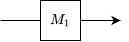

In [4]:
source = Source()
M1 = Machine(name='M1', cycle_time=1)
sink = Sink()

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[sink])
sink.define_routing(upstream=[M1])

system = System(objects=[source, M1, sink])

system.simulate(simulation_time=100)

Simulation finished in 0.01s
Parts produced: 100


### Single machine with degradation

An example of Markovian degradation of a single machine. The degradation matrix
specifies the health index transition probabilities. Once the machine reaches the
maximum health index it requires a corrective maintenance action to be restored. 

And cm_distribution indicates the distirubtion of 'time stamps' that a machine fails and corrective maintenance occurs. 
pm_distribution could also be used, which indicates the distribution of 'time stamps' to fix a machine that hasn't failed yet (under a condition-based or preventive maintenance policy, for example)

pm_distrubtion and cm_distrubution are both instances of simulation.distribution (override this to use other distributions outside of normal and geometric)

In [5]:
p = 0.1
degradation_matrix = np.array(
    [
        [1-p, p,   0.,  0.,  0.],
        [0.,  1-p, p,   0.,  0.],
        [0.,  0.,  1-p, p,   0.],
        [0.,  0.,  0.,  1-p, p ],
        [0.,  0.,  0.,  0.,  1.]
    ]
)
cm_distribution = {'geometric': 0.1}

In [6]:
source = Source()

M1 = Machine(
    name='M1', 
    cycle_time=10,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
sink = Sink()

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[sink])
sink.define_routing(upstream=[M1])

system = System(objects=[source, M1, sink])

random.seed(1)
system.simulate(simulation_time=utils.WEEK)

Simulation finished in 0.23s
Parts produced: 709


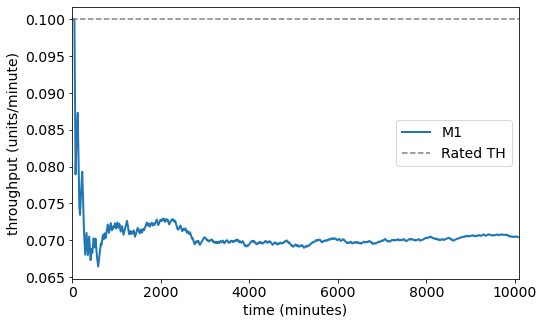

In [7]:
plot_throughput(system)

In [8]:
maintenance = pd.DataFrame(M1.maintenance_data)
maintenance_events = 'failure|begin maintenance|repaired'
maintenance[
    maintenance['event'].str.contains(maintenance_events)
]

,time,event
1,56,failure
2,56,begin maintenance
3,66,repaired
5,129,failure
6,129,begin maintenance
...,...,...
809,10050,failure
810,10050,begin maintenance
811,10057,repaired
813,10071,failure


---

### 2 machine 1 buffer, no degradation

<!--- $\rightarrow M_1\rightarrow B_1 \rightarrow M_2 \rightarrow$ -->

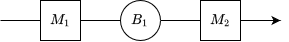

In [9]:
M1_cycle_time = 1
M2_cycle_time = 2

Simulation finished in 1.72s
Parts produced: 10079


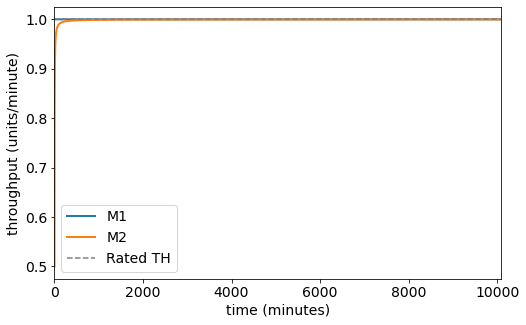

In [10]:
source = Source()
M1 = Machine(name='M1', cycle_time=1)
B1 = Buffer(capacity=5)
M2 = Machine(name='M2', cycle_time=1)
sink = Sink()

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=[M1], downstream=[M2])
M2.define_routing(upstream=[B1], downstream=[sink])
sink.define_routing(upstream=[M2])

system = System([source, M1, B1, M2, sink])

system.simulate(simulation_time=utils.WEEK)
plot_throughput(system)

### 2 machine 1 buffer line, with degradation


Simulation finished in 0.23s
Parts produced: 542


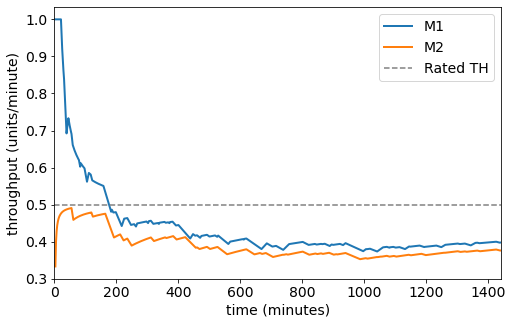

In [11]:
source = Source()
M1 = Machine(
    name='M1', 
    cycle_time=1,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
B1 = Buffer(capacity=10)
M2 = Machine(
    name='M2', 
    cycle_time=2,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
sink = Sink()

objects = [source, M1, B1, M2, sink]

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=[M1], downstream=[M2])
M2.define_routing(upstream=[B1], downstream=[sink])
sink.define_routing(upstream=[M2])

maintainer=Maintainer(capacity=1) #if not specified, default capacity=inf
system = System(objects=objects, maintainer=maintainer)
# system = System(objects=objects) if maintainer is not specified (and goes by default)

random.seed(1)
system.simulate(simulation_time=utils.DAY)

plot_throughput(system)

---

### 2 machine parallel line
<!--- $\rightarrow [M_1, M_2] \rightarrow$ -->

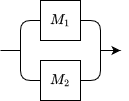

In [12]:
M1_cycle_time = 1
M2_cycle_time = 2

Simulation finished in 0.19s
Parts produced: 1743

M1 parts made: 1160
M2 parts made: 583


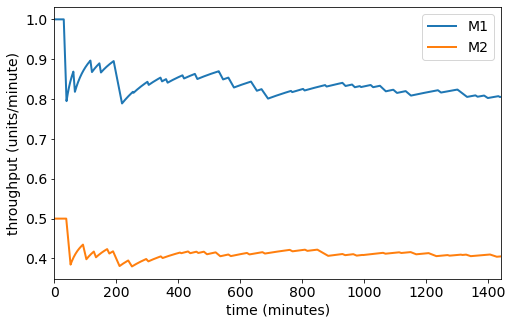

In [13]:
source = Source()
M1 = Machine(
    name='M1', 
    cycle_time=M1_cycle_time,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
M2 = Machine(
    name='M2', 
    cycle_time=M2_cycle_time,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
sink = Sink()

objects = [source, M1, M2, sink]

source.define_routing(downstream=[M1, M2])
M1.define_routing(upstream=[source], downstream=[sink])
M2.define_routing(upstream=[source], downstream=[sink])
sink.define_routing(upstream=[M1, M2])

system = System(objects=objects)

random.seed(1)
system.simulate(simulation_time=utils.DAY)

print(f'\nM1 parts made: {M1.parts_made}')
print(f'M2 parts made: {M2.parts_made}')

plot_throughput(system, plot_rated_throughput=False)

### Parallel stations
<!--- $\rightarrow [M_1, M_2] \rightarrow B_1 \rightarrow [M_3, M_4, M_5] \rightarrow B_2 \rightarrow [M_6, M_7] \rightarrow$ -->

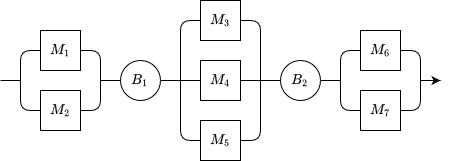

Simulation finished in 0.46s
Parts produced: 978

M1 parts made: 523
M2 parts made: 544
Station 1 parts made: 1067

M3 parts made: 334
M4 parts made: 310
M5 parts made: 359
Station 2 parts made: 1003

M1 parts made: 490
M2 parts made: 488
Station 3 parts made: 978

Total parts made: 978


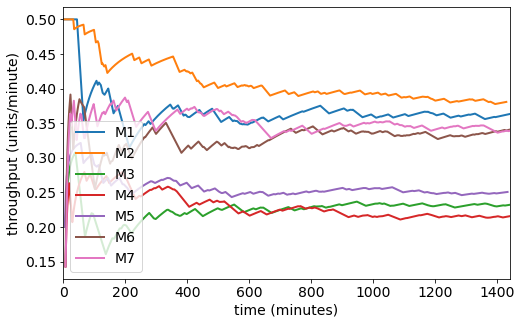

In [14]:
source = Source()

M1 = Machine('M1', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
M2 = Machine('M2', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)

station1 = [M1, M2]

B1 = Buffer(capacity=10)

M3 = Machine('M3', cycle_time=3, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
M4 = Machine('M4', cycle_time=3, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
M5 = Machine('M5', cycle_time=3, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)

station2 = [M3, M4, M5]

B2 = Buffer(capacity=10)

M6 = Machine('M6', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
M7 = Machine('M7', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)

station3 = [M6, M7]

sink = Sink()

source.define_routing(downstream=station1)

M1.define_routing(upstream=[source], downstream=[B1])
M2.define_routing(upstream=[source], downstream=[B1])

B1.define_routing(upstream=station1, downstream=station2)

M3.define_routing(upstream=[B1], downstream=[B2])
M4.define_routing(upstream=[B1], downstream=[B2])
M5.define_routing(upstream=[B1], downstream=[B2])

B2.define_routing(upstream=station2, downstream=station3)

M6.define_routing(upstream=[B2], downstream=[sink])
M7.define_routing(upstream=[B2], downstream=[sink])

sink.define_routing(upstream=station3)

objects = [source] + station1 + [B1] + station2 + [B2] + station3 + [sink]
#objects = [source, B1, B2, sink] + station1 + station2 + station3 

system = System(objects=objects)

random.seed(1)
system.simulate(simulation_time=utils.DAY)

print(f'\nM1 parts made: {M1.parts_made}')
print(f'M2 parts made: {M2.parts_made}')
print(f'Station 1 parts made: {M1.parts_made + M2.parts_made}\n')

print(f'M3 parts made: {M3.parts_made}')
print(f'M4 parts made: {M4.parts_made}')
print(f'M5 parts made: {M5.parts_made}')
print(f'Station 2 parts made: {M3.parts_made + M4.parts_made + M5.parts_made}\n')

print(f'M1 parts made: {M6.parts_made}')
print(f'M2 parts made: {M7.parts_made}')
print(f'Station 3 parts made: {M6.parts_made + M7.parts_made}\n')

print(f'Total parts made: {sink.level}')

plot_throughput(system, plot_rated_throughput=False)

---

### Complex configuration

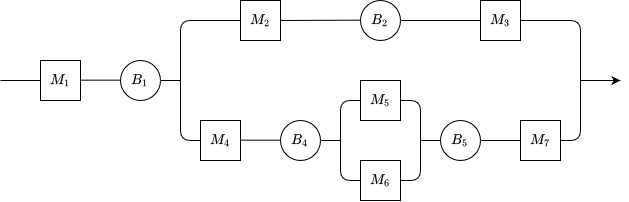

Simulation finished in 0.47s
Parts produced: 839

M1 parts made: 943
M2 parts made: 472
M3 parts made: 454
M4 parts made: 434
M5 parts made: 204
M6 parts made: 190
M7 parts made: 385

Total parts made: 839


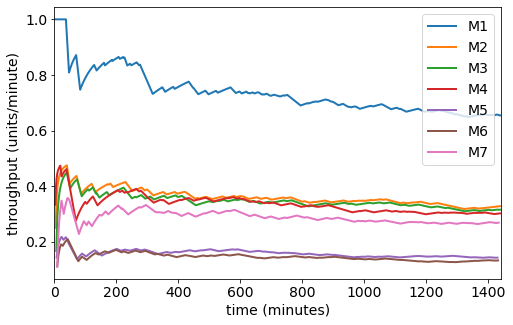

In [15]:
source = Source()

M1 = Machine('M1', cycle_time=1, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
B1 = Buffer(capacity=10)

M2 = Machine('M2', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
B2 = Buffer(capacity=5)
M3 = Machine('M3', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)

M4 = Machine('M4', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
B4 = Buffer(capacity=5)
M5 = Machine('M5', cycle_time=4, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
M6 = Machine('M6', cycle_time=4, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)
B5 = Buffer(capacity=5)
M7 = Machine('M7', cycle_time=2, degradation_matrix=degradation_matrix, cm_distribution=cm_distribution)

sink = Sink()

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])

B1.define_routing(upstream=[M1], downstream=[M2, M4])

M2.define_routing(upstream=[B1], downstream=[B2])
B2.define_routing(upstream=[M2], downstream=[M3])
M3.define_routing(upstream=[B2], downstream=[sink])
M4.define_routing(upstream=[B1], downstream=[B4])
B4.define_routing(upstream=[M4], downstream=[M5, M6])
M5.define_routing(upstream=[B4], downstream=[B5])
M6.define_routing(upstream=[B4], downstream=[B5])
B5.define_routing(upstream=[M5, M6], downstream=[M7])
M7.define_routing(upstream=[B5], downstream=[sink])

sink.define_routing(upstream=[M3, M7])

objects = [source, M1, M2, M3, M4, M5, M6, M7, B1, B2, B4, B5, sink]

system = System(objects=objects)

system.simulate(simulation_time=utils.DAY)

print()
for obj in objects:
    if type(obj) == Machine:
        print(f'{obj.name} parts made: {obj.parts_made}')

print(f'\nTotal parts made: {sink.level}')

plot_throughput(system, plot_rated_throughput=False)

## Maintenance

---

### Condition-based Maintenance

Example of a condition-based maintenance policy. The CBM threshold determines the health
index level at which a machine requests maintenance. 


Simulation finished in 0.14s
Parts produced: 581


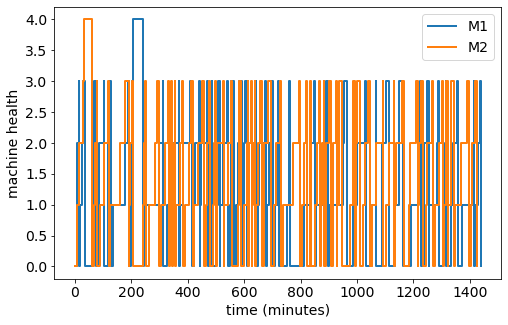

In [16]:
cm_distribution = {'geometric': 0.1}
pm_distribution = {'geometric': 0.25}

source = Source()
M1 = Machine(
    name='M1', 
    cycle_time=1,
    degradation_matrix=degradation_matrix,
    cbm_threshold=3,
    pm_distribution=pm_distribution,
    cm_distribution=cm_distribution
)
B1 = Buffer(capacity=10)
M2 = Machine(
    name='M2', 
    cycle_time=2,
    degradation_matrix=degradation_matrix,
    cbm_threshold=3,
    pm_distribution=pm_distribution,
    cm_distribution=cm_distribution
)
sink = Sink()

objects = [source, M1, B1, M2, sink]

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=[M1], downstream=[M2])
M2.define_routing(upstream=[B1], downstream=[sink])
sink.define_routing(upstream=[M2])

maintainer = Maintainer(capacity=1)

system = System(objects=objects, maintainer=maintainer)

random.seed(4)
system.simulate(simulation_time=utils.DAY)

plot_health(system)

## Simulation Functionality

---

### Simulation Replication 


This example compares the production of two systems, one under a corrective maintenance
policy and the other under a condition-based maintenance policy. The simulation
replication functionality is used to estimate the average production of both systems. 


In [17]:
degradation_matrix = utils.generate_degradation_matrix(h_max=10, p=0.1)

cm_distribution = {'geometric': 0.1}
pm_distribution = {'geometric': 0.15}

# CM Policy
source = Source()
M1 = Machine(
    name='M1', 
    cycle_time=1,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
B1 = Buffer(capacity=10)
M2 = Machine(
    name='M2', 
    cycle_time=2,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution
)
sink = Sink()

objects = [source, M1, B1, M2, sink]

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=[M1], downstream=[M2])
M2.define_routing(upstream=[B1], downstream=[sink])
sink.define_routing(upstream=[M2])

maintainer = Maintainer(capacity=1)

corrective_maintenance_system = System(objects=objects, maintainer=maintainer)

# CBM Policy (Define the condition-based maintenance system)
source = Source()
M1 = Machine(
    name='M1', 
    cycle_time=1,
    degradation_matrix=degradation_matrix,
    cbm_threshold=8,
    pm_distribution=pm_distribution,
    cm_distribution=cm_distribution
    
)
B1 = Buffer(capacity=10)
M2 = Machine(
    name='M2', 
    cycle_time=2,
    degradation_matrix=degradation_matrix,
    cbm_threshold=8,
    pm_distribution=pm_distribution,
    cm_distribution=cm_distribution
)
sink = Sink()

objects = [source, M1, B1, M2, sink]

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=[M1], downstream=[M2])
M2.define_routing(upstream=[B1], downstream=[sink])
sink.define_routing(upstream=[M2])

maintainer = Maintainer(capacity=1)

condition_based_maintenance_system = System(objects=objects, maintainer=maintainer)

In [18]:
# Simulate both systems

random.seed(1)

replications = 50

corrective_maintenance_results = corrective_maintenance_system.iterate_simulation(
    replications=replications, warm_up_time=utils.DAY, simulation_time=utils.WEEK, jobs=10
) #, verbose=False)

condition_based_maintenance_results = condition_based_maintenance_system.iterate_simulation(
    replications=replications, warm_up_time=utils.DAY, simulation_time=utils.WEEK, jobs=10
) #, verbose=False)

cm_production = [r[0] for r in corrective_maintenance_results]
cbm_production = [r[0] for r in condition_based_maintenance_results]


cm_average = sum(cm_production) / replications
cbm_average = sum(cbm_production) / replications

print(f'Average corrective maintenance production:       {cm_average:.2f} units')
print(f'Average condition-based maintenance production:  {cbm_average:.2f} units')

Finished 50 replications in 18.25s
Finished 50 replications in 21.47s
Average corrective maintenance production:       4481.60 units
Average condition-based maintenance production:  4605.32 units


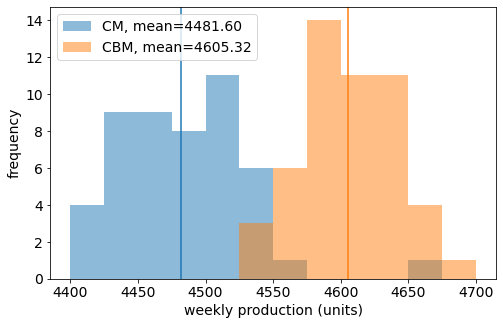

In [19]:
plt.figure(figsize=(8,5))

cm_mean = np.mean(cm_production)
cbm_mean = np.mean(cbm_production)

bins = np.arange(4400, 4701, 25)
plt.hist(cm_production, bins=bins, alpha=0.5, label=f'CM, mean={cm_mean:.2f}')
plt.hist(cbm_production, bins=bins, alpha=0.5, label=f'CBM, mean={cbm_mean:.2f}')

plt.axvline(x=cm_mean, color='C0')
plt.axvline(x=cbm_mean, color='C1')

plt.xlabel('weekly production (units)')
plt.ylabel('frequency')

plt.legend()
plt.show()

---

### Exporting System State

In [20]:
pickle.dump(condition_based_maintenance_system, open('cbm_system.pkl', 'wb'))

In [21]:
system = pickle.load(open('cbm_system.pkl', 'rb'))

system.simulate(simulation_time=utils.WEEK)

Simulation finished in 1.63s
Parts produced: 4588


---

## Maintenance Opimization

---

### CBM Optimization

Simulation finished in 0.01s
Parts produced: 32


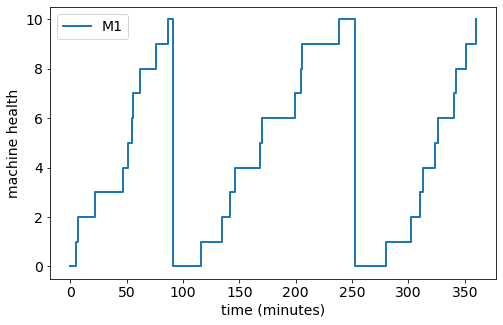

In [22]:
degradation_matrix = utils.generate_degradation_matrix(h_max=10, p=0.1)

cm_distribution = {'geometric': 0.1}
pm_distribution = {'geometric': 0.25}

source = Source()
M1 = Machine(
    'M1',
    cycle_time=10,
    degradation_matrix=degradation_matrix,
    pm_distribution=pm_distribution,
    cm_distribution=cm_distribution
)
sink = Sink()

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[sink])
sink.define_routing(upstream=[M1])

system = System([source, M1, sink])

system.simulate(simulation_time=360)

plot_health(system)

In [23]:
policy_results = []
for cbm_threshold in range(1, len(degradation_matrix)):
    for machine in system.machines:
        machine.cbm_threshold = cbm_threshold
        
    policy_replications = system.iterate_simulation(
        replications=10, warm_up_time=utils.DAY, simulation_time=utils.WEEK, jobs=10, verbose=False
    )
    policy_results.append([r[0] for r in policy_replications])

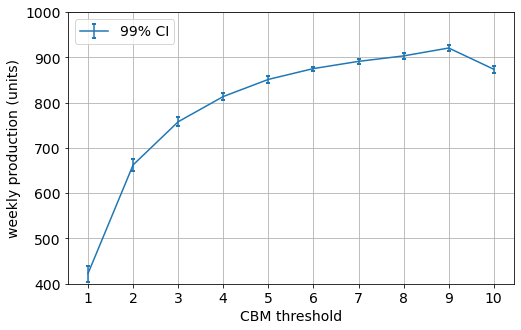

In [24]:
def mean_ci(data, confidence=0.99):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2., n-1)
    return m-h, m+h

cis = np.apply_along_axis(mean_ci, 1, np.array(policy_results))

plt.figure(figsize=(8,5))

plt.errorbar(
    range(1, len(degradation_matrix)), 
    [np.mean(prod) for prod in policy_results], 
    (cis[:,1]-cis[:,0])/2,
    capsize=2,
    capthick=2,
    label='99% CI'
)

plt.xlabel('CBM threshold')
plt.ylabel('weekly production (units)')

plt.xticks(range(1, 11))
plt.ylim([400, 1000])

plt.grid()
plt.legend(loc='upper left')
plt.show()

---

## Example Class Extensions (for Maintainer, Machine, & Part)

### Maintainer Class Extension Example (For Alternative Maintenance Policies)

An example of the extensibility of the Maintainer class. A "least processing time first"
(LPT) policy is implemented.


In [25]:
class LptMaintainer(Maintainer):
    """Chooses the machine with the longest expected repair time first."""
    def choose_maintenance_action(self, queue):
        def expected_repair_time(machine):
            if machine.failed: # Machine requires corrective maintenance
                return machine.cm_distribution.mean
            else: # Machine requires preventive maintenance
                return machine.pm_distribution.mean
                
        return max(queue, key=expected_repair_time)
    
maintainer = LptMaintainer()

In [26]:
degradation_matrix = [
    [0.9, 0.1, 0.,  0.,  0. ],
    [0.,  0.9, 0.1, 0.,  0. ],
    [0.,  0.,  0.9, 0.1, 0. ],
    [0.,  0.,  0.,  0.9, 0.1],
    [0.,  0.,  0.,  0.,  1. ]
]

In [27]:
    source = Source()
    M1 = Machine(
        name='M1', 
        cycle_time=1,
        degradation_matrix=degradation_matrix,
        cm_distribution={'geometric': 0.1}
    )
    B1 = Buffer(capacity=10)
    M2 = Machine(
        name='M2', 
        cycle_time=1,
        degradation_matrix=degradation_matrix,
        cm_distribution={'geometric': 0.075}
    )
    B2 = Buffer(capacity=10)
    M3 = Machine(
        name='M3', 
        cycle_time=1,
        degradation_matrix=degradation_matrix,
        cm_distribution={'geometric': 0.05}
    )
    sink = Sink()

    source.define_routing(downstream=[M1])
    M1.define_routing(upstream=[source], downstream=[B1])
    B1.define_routing(upstream=[M1], downstream=[M2])
    M2.define_routing(upstream=[B1], downstream=[B2])
    B2.define_routing(upstream=[M2], downstream=[M3])
    M3.define_routing(upstream=[B2], downstream=[sink])
    sink.define_routing(upstream=[M3])

    objects = [source, M1, B1, M2, B2, M3, sink]
    maintainer = LptMaintainer()

    system = System(objects, maintainer)

    random.seed(1)
    system.simulate(simulation_time=utils.WEEK)

Simulation finished in 1.97s
Parts produced: 5333


### Machine Class Extension Example

An example of extensible machine behavior. Random noise is added to machine health index
readings and monitored periodically instead of continuously. 

And also an interesting way of printing true health and corresponding 
machine health sensor readings.

In [28]:
class SensingEvent(simulation.Event):
    # A new event type is used to assign the correct priority to the sensing event. In
    # this case, sensing events are scheduled just after machine degradation events.
    def get_action_priority(self):
        return 5.5

In [29]:
class ConditionMonitoredMachine(Machine):
    def __init__(self, sensing_interval=1, sensor_noise=0, **kwargs):
        self.sensing_interval = sensing_interval
        self.sensor_noise = sensor_noise
        self.sensor_data = {'time': [], 'reading': []}
        
        super().__init__(**kwargs)
    
    def initialize_addon_process(self):
        self.env.schedule_event(
            time=self.env.now, 
            location=self, 
            action=self.sense, 
            source=f'{self.name} initial addon process',
            event_type=SensingEvent
        )
        
    def repair_addon_process(self):
        self.env.schedule_event(
            time=self.env.now,
            location=self,
            action=self.sense,
            source=f'{self.name} repair addon process at {self.env.now}',
            event_type=SensingEvent
        )
    
    def sense(self):
        self.sensor_reading = self.health + np.random.normal(0, self.sensor_noise)
        
        self.sensor_data['time'].append(self.env.now)
        self.sensor_data['reading'].append(self.sensor_reading)
        
        self.env.schedule_event(
            time=self.env.now+self.sensing_interval,
            location=self,
            action=self.sense,
            source=f'{self.name} sensing at {self.env.now}',
            event_type=SensingEvent
        )

In [30]:
degradation_matrix = utils.generate_degradation_matrix(h_max=5, p=0.3)
cm_distribution = {'geometric': 0.1}

source = Source()
M1 = ConditionMonitoredMachine(
    name='M1',
    cycle_time=2,
    degradation_matrix=degradation_matrix,
    cm_distribution=cm_distribution,
    sensing_interval=1,
    sensor_noise=0.3
)
sink = Sink()

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[sink])
sink.define_routing(upstream=[M1])

system = System(objects=[source, M1, sink])

#random.seed(1)
system.simulate(simulation_time=6*60)

Simulation finished in 0.03s
Parts produced: 129


In [31]:
# Print true health and corresponding sensor reading
rows = 12
print('\ntime  health  sensor reading')

for time, reading in zip(
    M1.sensor_data['time'][:rows], M1.sensor_data['reading'][:rows]
):
    timestamp = max([t for t in M1.health_data['time'] if t <= time])
    idx = M1.health_data['time'].index(timestamp)
    health = M1.health_data['health'][idx]
    print(f'{time:<4}  {health:<3}    {reading:>8.4f}')


time  health  sensor reading
0     0        0.3356
1     1        0.9826
2     2        1.8933
3     2        2.0198
4     2        2.1667
5     2        1.7153
6     3        2.9249
7     4        4.2524
8     5        4.9181
13    0       -0.1548
14    0        0.1496
15    0        0.5867


### Part Class Extension Example

Also an alternative way of printing part qualities of parts passed through each machine

In [32]:
class QualityPart(Part):
    def initialize(self):
        self.quality = 1.0

In [33]:
class PartQualityMonitorMachine(Machine):
    def __init__(self, quality_distribution, **kwargs):
        # Quality distribution should return a value on [0, 1]
        self.quality_distribution = quality_distribution
        
        super().__init__(**kwargs)
    
    def output_addon_process(self, part):
        part.quality *= self.quality_distribution()

In [34]:
source = Source(part_type=QualityPart)
M1 = PartQualityMonitorMachine(
    name='M1',
    quality_distribution=lambda: 1-0.1*random.random(), # [0.9, 1.0]
    cycle_time=1
)
B1 = Buffer('B1', capacity=10)
M2 = PartQualityMonitorMachine(
    name='M2',
    quality_distribution=lambda: 0.8-0.2*random.random(), # [0.6, 0.8]
    cycle_time=2
)
M3 = PartQualityMonitorMachine(
    name='M3',
    quality_distribution=lambda: 0.6-0.3*random.random(), # [0.3, 0.6]
    cycle_time=2
)
sink = Sink(collect_parts=True)

source.define_routing(downstream=[M1])
M1.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=[M1], downstream=[M2, M3])
M2.define_routing(upstream=[B1], downstream=[sink])
M3.define_routing(upstream=[B1], downstream=[sink])
sink.define_routing(upstream=[M2, M3])

system = System([source, M1, B1, M2, M3, sink])

random.seed(1)
system.simulate(simulation_time=utils.DAY)

Simulation finished in 0.22s
Parts produced: 1438


In [35]:
for machine in system.machines:
    machine_parts = [
        part for part in sink.contents if machine.name in part.routing_history
    ]
    average_quality = (
        sum([part.quality for part in machine_parts]) / machine.parts_made
    )
    print(f'{machine.name} average part quality: {average_quality:.2%}')


M1 average part quality: 54.49%
M2 average part quality: 66.36%
M3 average part quality: 42.77%


---

## Simantha Limitations with Recurrent Flows

In this first example, there are 3 stages of machines in series. 
Each stage represents a 'group' of machines.

Note that Stage 1 & 3 share the machine M99 --> This is a recurrent flow.
However, simulation results will show that M99 is only used in one of the stages.

In [36]:
source = Source()

M1 = Machine(name='M1', cycle_time=1)
M99 = Machine(name='M99', cycle_time=1)
stage1 = [M1,M99]
B1 =Buffer(capacity=10)


M2 = Machine(name='M2', cycle_time=1)
stage2 = [M2]
B2 = Buffer(capacity=10)

M3 = Machine(name='M3', cycle_time=1)
#Recurrent flow in Stage 3(M99 is also used in Stage 1)
stage3 = [M99, M3] 

sink = Sink(collect_parts=True)


source.define_routing(downstream=stage1)
for machine in stage1:
    machine.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=stage1, downstream=stage2)
for machine in stage2:
    machine.define_routing(upstream=[B1], downstream=[B2])
B2.define_routing(upstream=stage2, downstream=stage3)
for machine in stage3:
    machine.define_routing(upstream=[B2], downstream=[sink])
sink.define_routing(upstream=stage3)

#objects = [source] + station1 + [B1] + station2 + [B2] + station3 + [sink]
objects = [source, B1, B2, sink] + stage1 + stage2 + stage3  

system = System(objects)

system.simulate(simulation_time=500)
#   system.simulate(simulation_time=utils.WEEK)


Simulation finished in 0.17s
Parts produced: 498


In [37]:
# Observe the lack of recurrent flow in M99's routing history of parts
# i.e., M99 was only used in one stage

M99_part_history = [
    part.routing_history for part in sink.contents if M99.name in part.routing_history
]
#len(machine_parts)
M99_part_history

[['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 'M99'],
 ['M1', 'Buffer', 'M2', 'Buffer', 

---

In this second example, there are 4 stages of machines in series. 
Each stage represents a 'group' of machines.

Note that Stages 2 & 4 share M2, M3, and M4. Stage 2 has an additional machine, M7. 
However, simulation results will show that M7 and the group [M2, M3, M4] are used in distinct stages. 

In fact, **if Stage 2 did not have the extra M7** (as in Stage 2 and Stage 4 are the same), then the simulation would break. Also, the simulation breaks if Stage 4 has the extra M7 instead of Stage 2. 

In [38]:
source = Source()

M1 = Machine(name='M1', cycle_time=1)
stage1 = [M1]
B1 =Buffer(capacity=40)


M2 = Machine(name='M2', cycle_time=1)
M3 = Machine(name='M3', cycle_time=1)
M4 = Machine(name='M4', cycle_time=1)
M7 = Machine(name='M7', cycle_time=1)
stage2 = [M2, M3, M4, M7]
stage4 = [M2, M3, M4]
B2 = Buffer(capacity=40)
sink = Sink(collect_parts=True)


M5 = Machine(name='M5', cycle_time=1)
M6 = Machine(name='M6', cycle_time=1)
stage3 = [M5, M6]
B3 = Buffer(capacity=10)


source.define_routing(downstream=stage1)
for machine in stage1:
    machine.define_routing(upstream=[source], downstream=[B1])
B1.define_routing(upstream=stage1, downstream=stage2)
for machine in stage2:
    machine.define_routing(upstream=[B1], downstream=[B2])
B2.define_routing(upstream=stage2, downstream=stage3)
for machine in stage3:
    machine.define_routing(upstream=[B2], downstream=[B3])
B3.define_routing(upstream=stage3, downstream=stage4)
for machine in stage4:
    machine.define_routing(upstream=[B3], downstream=[sink])
sink.define_routing(upstream=stage4)

objects = [source, B1, B2, B3, sink] + stage1 + stage2 + stage3 + stage4 

system = System(objects)

system.simulate(simulation_time=100)
#   system.simulate(simulation_time=utils.WEEK)
print(f'\nM1 parts made: {M1.parts_made}')
print(f'M2 parts made: {M2.parts_made}')
print(f'M3 parts made: {M3.parts_made}')
print(f'M4 parts made: {M4.parts_made}')
print(f'M5 parts made: {M5.parts_made}')
print(f'M6 parts made: {M6.parts_made}')
print(f'M7 parts made: {M7.parts_made}')

Simulation finished in 0.06s
Parts produced: 97

M1 parts made: 100
M2 parts made: 29
M3 parts made: 30
M4 parts made: 38
M5 parts made: 47
M6 parts made: 51
M7 parts made: 99


In [39]:
# Observe the lack of recurrent flow in M2's routing history of parts
# i.e., M2 was only used in one stage despite being part of Stages 2 & 4
# in the simulation setup

#The same is true for M3 and M4. 

M2_part_history = [
    part.routing_history for part in sink.contents if M2.name in part.routing_history
]
#len(machine_parts)
M2_part_history

[['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M5', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M5', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M5', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M5', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M5', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M6', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer', 'M5', 'Buffer', 'M2'],
 ['M1', 'Buffer', 'M7', 'Buffer